# Do market states improve next-session risk forecasts?

## Summary

Through 2026-09-17, the late-segment two-state HMM minus EWMA mean next-session risk loss is **+0.2539**, with paired 95% block interval **[-0.1024, +0.8795]**. Negative favors HMM. The result does not establish incremental forecasting value, and does not establish general regime-prediction ability.

## Context and methods

# Description, detection, and forecasting are different tasks

A historical color map can organize market behavior even when it cannot improve a decision.
The study therefore asks the forecast question first. SPY represents equity risk; TLT adds a
rate-sensitive asset that may distinguish equity stress from joint stock/bond shocks.

## What each model knows

A Gaussian mixture treats observations as iid draws from several Gaussian components. Its
posterior classifies the current observation; its next-observation distribution still uses
mixture weights. A hidden Markov model adds transition probabilities A_ij. It can carry a
persistent state belief from one date into the next.

At a monthly refit, 504 trailing observations determine scaling, component parameters and
state order. High risk means a higher fitted SPY second moment, not recession status. Models
learn from earlier evaluation observations as time advances, but never from future ones.
Between refits, the HMM uses one forward update:

alpha_t(j) proportional to f_j(x_t) sum_i alpha_(t-1)(i) A_ij.

Normalize in log space, then next-state probabilities are alpha_t A. The forecast is the
probability-weighted sum of state variance plus squared state mean, mapped back to decimal
SPY return units. The known-parameter test enumerates every short hidden-state path and
compares the exact posterior with the recursion. Future perturbations must leave saved
forecast prefixes unchanged.

Full-sequence library posterior/decoding methods can use future observations. Here they are
confined to retrospective diagnostics. Comparing those descriptions with archived filters
shows how appealing historical labels can revise. No state is independently labeled a recession.

## The forecast contest

The target is next-session squared SPY return. EWMA uses decay .94; a single-state trailing
second moment is another baseline. Loss is log(v)+r_next^2/v, with positive forecast floor
1e-8. Pairwise differences matter; the log term means negative loss levels are normal.
Daily squared returns are noisy risk proxies, not measured latent conditional volatility.
The primary HMM/EWMA contrast uses 428 late-segment forecasts through 17 September 2026.

HMM's `min_covar` is an initialization floor in the installed implementation, while GMM's
`reg_covar` adds diagonal regularization. The floor sensitivity records these exact API
settings; it is not a promise that every fitted HMM variance is bounded by that number.
Reaching an EM iteration limit alone does not pass convergence; the last likelihood gain
and finite positive covariances are checked. Failed fits explicitly use EWMA.

## A decision requires another timing assumption

The overlay maps high-risk probability p to SPY weight 1-.75p. It trades one session after
observation and first earns the next return, so its executable horizon differs from the
one-step forecast score. A static .625 control and capped 10%-volatility EWMA rule make
exposure reductions visible. All use exact self-financing costs and zero assumed cash interest.

## Change points with known truth

The independent greedy Gaussian splitter optimizes one mean/variance likelihood break at a
time; it omits the original GGS breakpoint refinement and multivariate optimization. Market
splits are retrospective. An expanding-prefix synthetic alarm records detection date separately
from estimated breakpoint; 50 null and 50 variance-break paths quantify false alarms and delay.
The artificial 3x volatility jump is an algorithm check, not market ground truth.

[Forecast and decision results](docs/02-results.md) · [Frozen settings and caveats](research/PROTOCOL.md).


### Recompute from pinned inputs

Runs the maintained pipeline, reusing matching checkpoints where available. No notebook-only model logic.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from research.run_study import main
from research.common import ROOT, RESULTS, FIGURES
main()

Computed primary


Computed three_states


Computed seed41


Computed floor01


Computed spy_only


Through 2026-09-17, the late-segment two-state HMM minus EWMA mean next-session risk loss is **+0.2539**, with paired 95% block interval **[-0.1024, +0.8795]**. Negative favors HMM. The result does not establish incremental forecasting value, and does not establish general regime-prediction ability.


## Data

Input provenance records the exact vintage or the explicitly illustrative fixture. Retrieval dates do not imply historical availability.

In [2]:
manifest = json.loads((ROOT / "research/data/input_manifest.json").read_text())
display(Markdown("Input kind: **" + manifest.get("kind", "observed adjusted-close snapshots") + "**"))
sources = pd.DataFrame(manifest.get("snapshots", manifest.get("inputs", [])))
columns = [c for c in ["ticker", "rows", "first_date", "last_date", "path"] if c in sources]
display(sources[columns].head(10))

Input kind: **observed adjusted-close snapshots**

,ticker,rows,first_date,last_date
0,SPY,2064,2018-07-02,2026-09-17
1,TLT,2064,2018-07-02,2026-09-17


## Results

In [3]:
import re
text = (ROOT / "docs/02-results.md").read_text()
text = re.sub(r"!\[[^\]]*\]\([^)]*\)", "", text)
display(Markdown(text.replace("../research/", "research/").replace("(01-methods.md)", "(docs/01-methods.md)")))

# Do market states improve risk forecasts?

Through 2026-09-17, the late-segment two-state HMM minus EWMA mean next-session risk loss is **+0.2539**, with paired 95% block interval **[-0.1024, +0.8795]**. Negative favors HMM. The result does not establish incremental forecasting value, and does not establish general regime-prediction ability.



## Forecast evidence

| period | model | n | mean_loss | mean_forecast | realized_to_predicted |
| --- | --- | --- | --- | --- | --- |
| late | EWMA | 428 | -8.31006 | 0.000118494 | 0.988801 |
| late | GMM | 428 | -7.73757 | 0.000100289 | 1.16829 |
| late | HMM | 428 | -8.05618 | 9.00073e-05 | 1.30175 |
| late | Single state | 428 | -7.73709 | 0.000100189 | 1.16946 |

The loss uses the same next-session squared SPY return for all models. Its absolute level is not a performance percentage. A GMM is an iid mixture; its current posterior is not a Markov next-state forecast. HMM decisions use forward filtering, not full-sample smoothing.

## Bounded sensitivity

| variant | estimate | lower95 | upper95 | block | draws | n | failed_hmm_refits | refits |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| primary | 0.253878 | -0.102351 | 0.879465 | 21 | 2000 | 428 | 0 | 74 |
| three_states | 0.266082 | -0.120088 | 0.951861 | 21 | 2000 | 428 | 1 | 74 |
| seed41 | 0.248807 | -0.10677 | 0.880139 | 21 | 2000 | 428 | 0 | 74 |
| floor01 | 0.253897 | -0.102353 | 0.87955 | 21 | 2000 | 428 | 0 | 74 |
| spy_only | 0.293272 | -0.0978238 | 1.00043 | 21 | 2000 | 428 | 0 | 74 |

One primary HMM/EWMA comparison; these extra intervals are pointwise exploratory diagnostics, not independent confirmations. Failed fits use EWMA and are counted.

## Decisions after execution costs

| strategy | cagr | volatility | max_drawdown | annual_turnover | mean_risky_weight |
| --- | --- | --- | --- | --- | --- |
| EWMA target | 0.0736075 | 0.105281 | -0.120395 | 5.22185 | 0.731952 |
| HMM overlay | 0.141474 | 0.124193 | -0.112003 | 16.2087 | 0.886616 |
| Static 62.5% | 0.112192 | 0.107285 | -0.120658 | 0.414957 | 0.625 |

The overlay trades one close after the signal and first earns the following session. This delay differs from the one-step forecast target; lower exposure can explain safer returns. Zero cash accrual, closing fills, fixed surviving ETFs and revised adjusted closes limit investability.

## Description, detection and prediction

The synthetic null alarm rate is 0.0% across 50 runs. The variance-break example detects after the change in 100.0% of runs; conditional mean delay is 12.4 observations. These are constructed variance changes, not labeled market recessions. The simplified greedy splitter is not the complete optimized GGS algorithm.



Full-sample states revise historical labels using information unavailable then. This is useful historical organization but cannot substitute for the forecast comparison. No state is called a recession. Consult [methods](docs/01-methods.md), [protocol](research/PROTOCOL.md), [sources](research/SOURCES.md), and [next experiment](research/RESEARCH_AGENDA.md).


### Forecast metrics

In [4]:
display(pd.read_csv(RESULTS / "forecast_metrics.csv").round(6).head(30))

,period,model,n,mean_loss,mean_forecast,realized_to_predicted
0,full,EWMA,1538,-8.284497,0.000112,0.991848
1,full,GMM,1538,-7.911118,0.000157,0.708494
2,full,HMM,1538,-8.165364,0.000130,0.854097
3,full,Single state,1538,-7.911186,0.000157,0.709201
4,late,EWMA,428,-8.310058,0.000118,0.988801
5,late,GMM,428,-7.737573,0.000100,1.168294
6,late,HMM,428,-8.056180,0.000090,1.301748
7,late,Single state,428,-7.737089,0.000100,1.169456


### Diagnostics

In [5]:
display(pd.read_csv(RESULTS / "diagnostics.csv").round(6).head(30))

,refits,hmm_failed_refits,gmm_failed_refits,fallback_forecast_days,mean_high_probability,mean_entropy,hard_label_persistence,retrospective_label_disagreement
0,74,0,0,0,0.294853,0.181716,0.934938,0.152796


### Overlay performance

In [6]:
display(pd.read_csv(RESULTS / "overlay_performance.csv").round(6).head(30))

,cost_bps,strategy,n,annual_mean,cagr,volatility,mean_over_vol_rf0,max_drawdown,terminal_wealth,annual_turnover,mean_risky_weight
0,0,EWMA target,428,0.079188,0.076414,0.105279,0.752174,-0.119911,1.133220,5.221983,0.731952
1,0,HMM overlay,428,0.148184,0.150763,0.124229,1.192823,-0.109493,1.269344,16.209973,0.886616
2,0,Static 62.5%,428,0.112272,0.112423,0.107287,1.046468,-0.120613,1.198355,0.414945,0.625000
3,5,EWMA target,428,0.076577,0.073608,0.105281,0.727360,-0.120395,1.128206,5.221845,0.731952
4,5,HMM overlay,428,0.140070,0.141474,0.124193,1.127845,-0.112003,1.251990,16.208718,0.886616
5,5,Static 62.5%,428,0.112065,0.112192,0.107285,1.044548,-0.120658,1.197933,0.414957,0.625000
6,10,EWMA target,428,0.073966,0.070808,0.105282,0.702546,-0.120879,1.123214,5.221709,0.731952
7,10,HMM overlay,428,0.131958,0.132260,0.124163,1.062778,-0.114506,1.234874,16.207467,0.886616
8,10,Static 62.5%,428,0.111857,0.111961,0.107284,1.042629,-0.120702,1.197511,0.414969,0.625000


### States

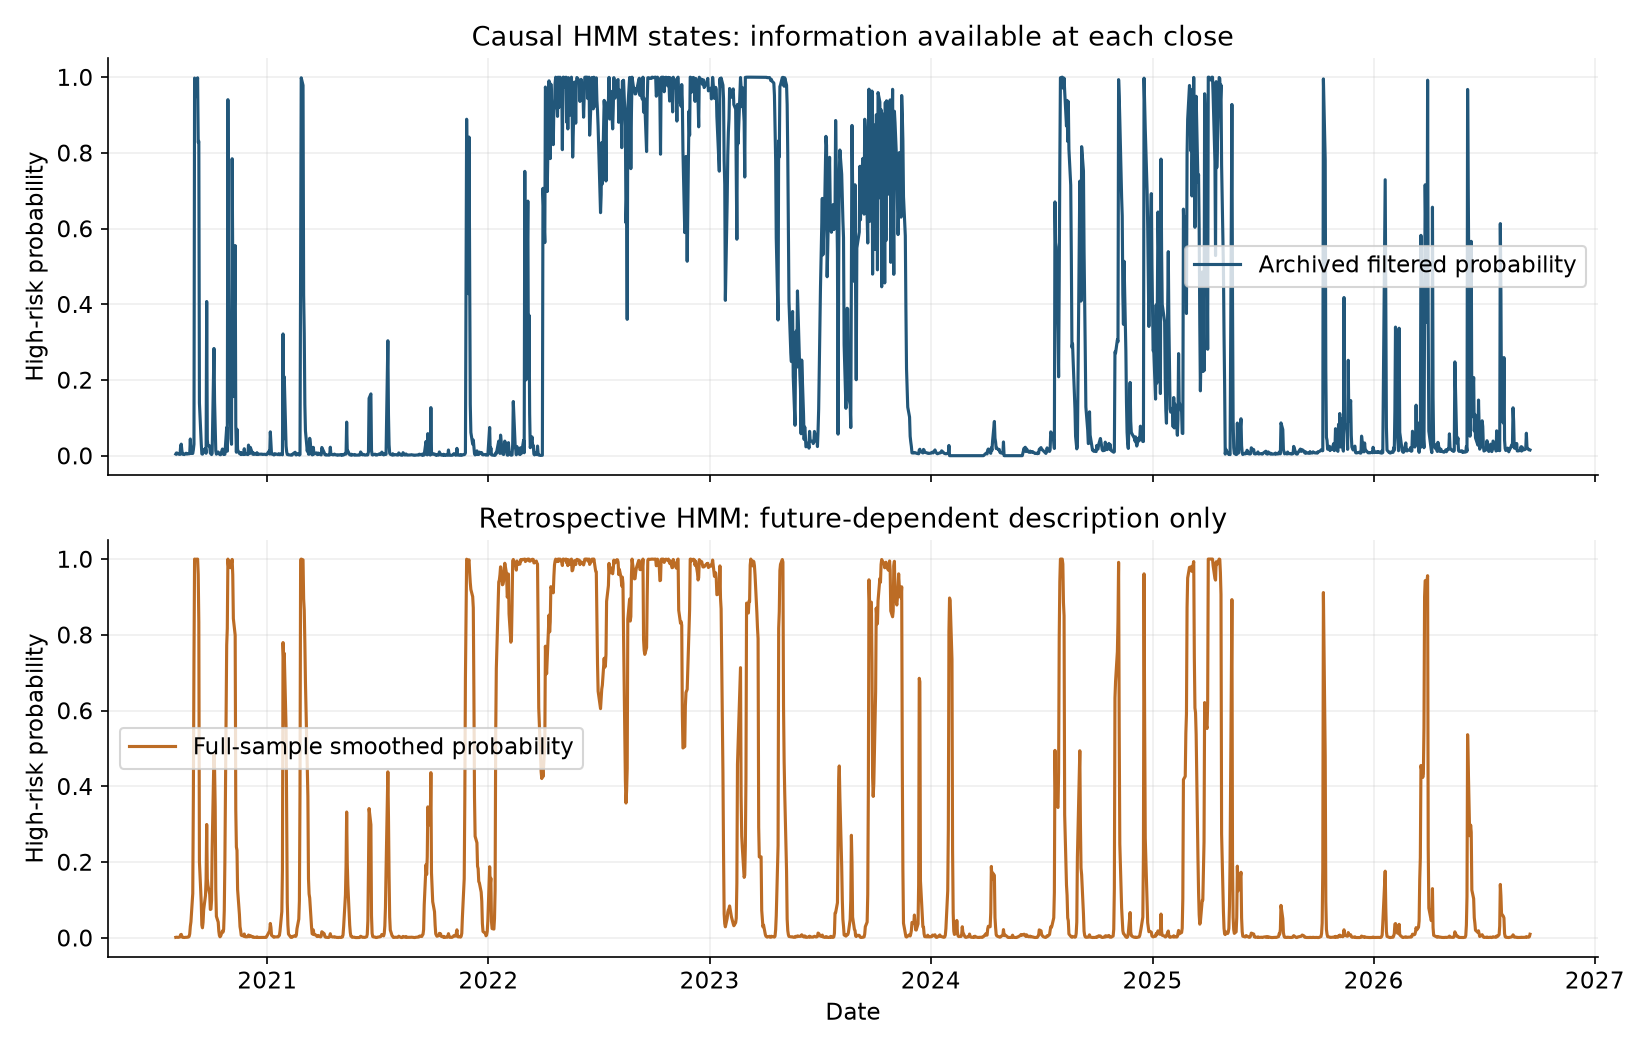

In [7]:
display(Image(filename=str(FIGURES / "states.png")))

### Forecast comparison

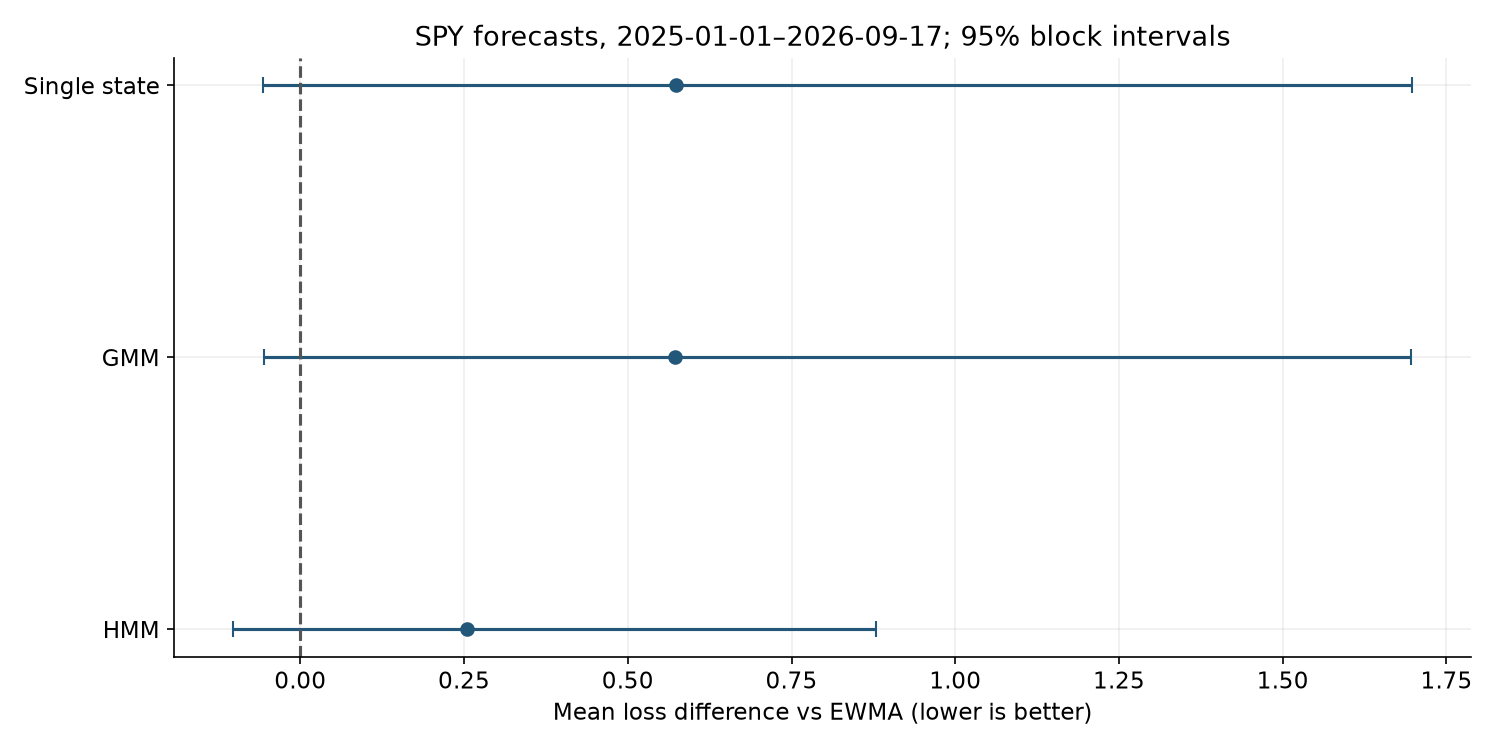

In [8]:
display(Image(filename=str(FIGURES / "forecast_comparison.png")))

### Revisions

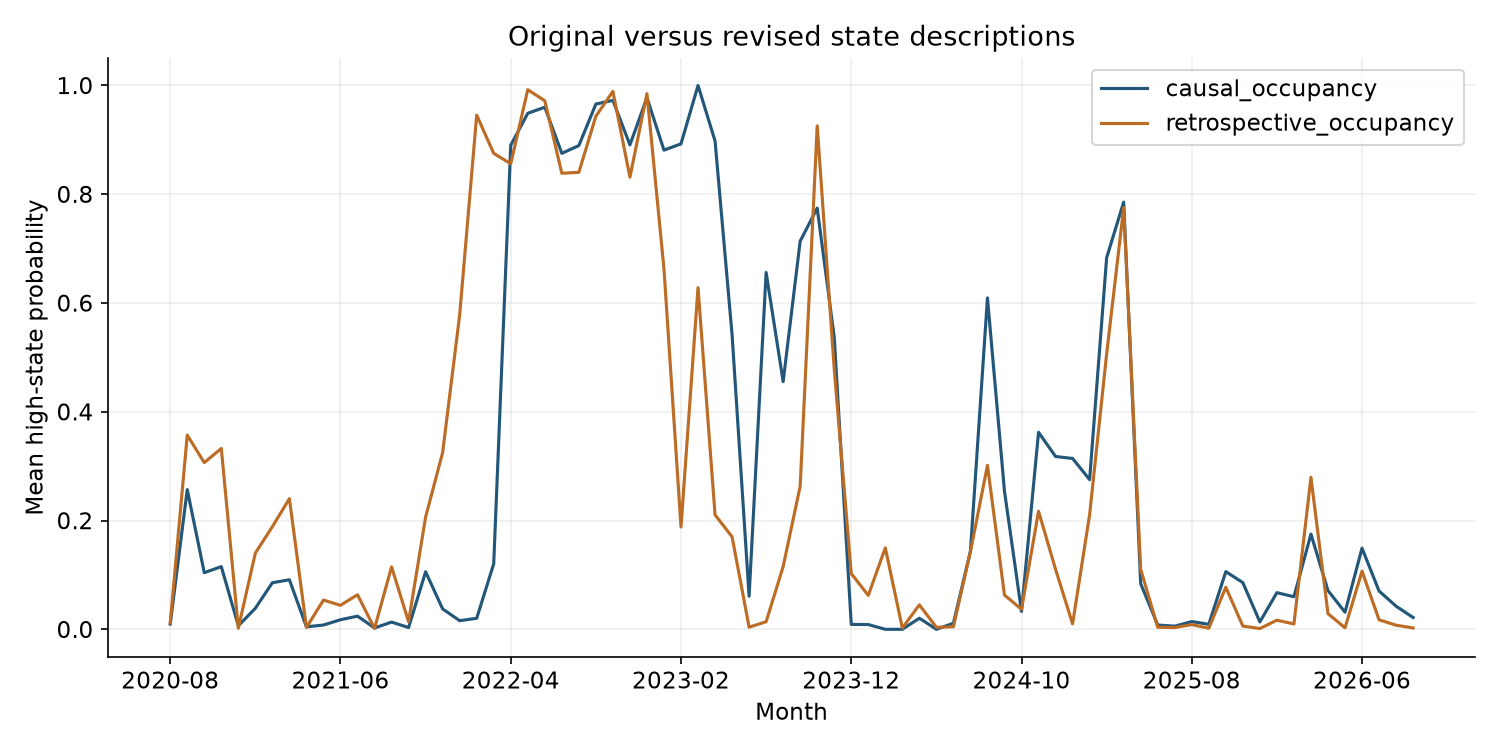

In [9]:
display(Image(filename=str(FIGURES / "revisions.png")))

### Overlay

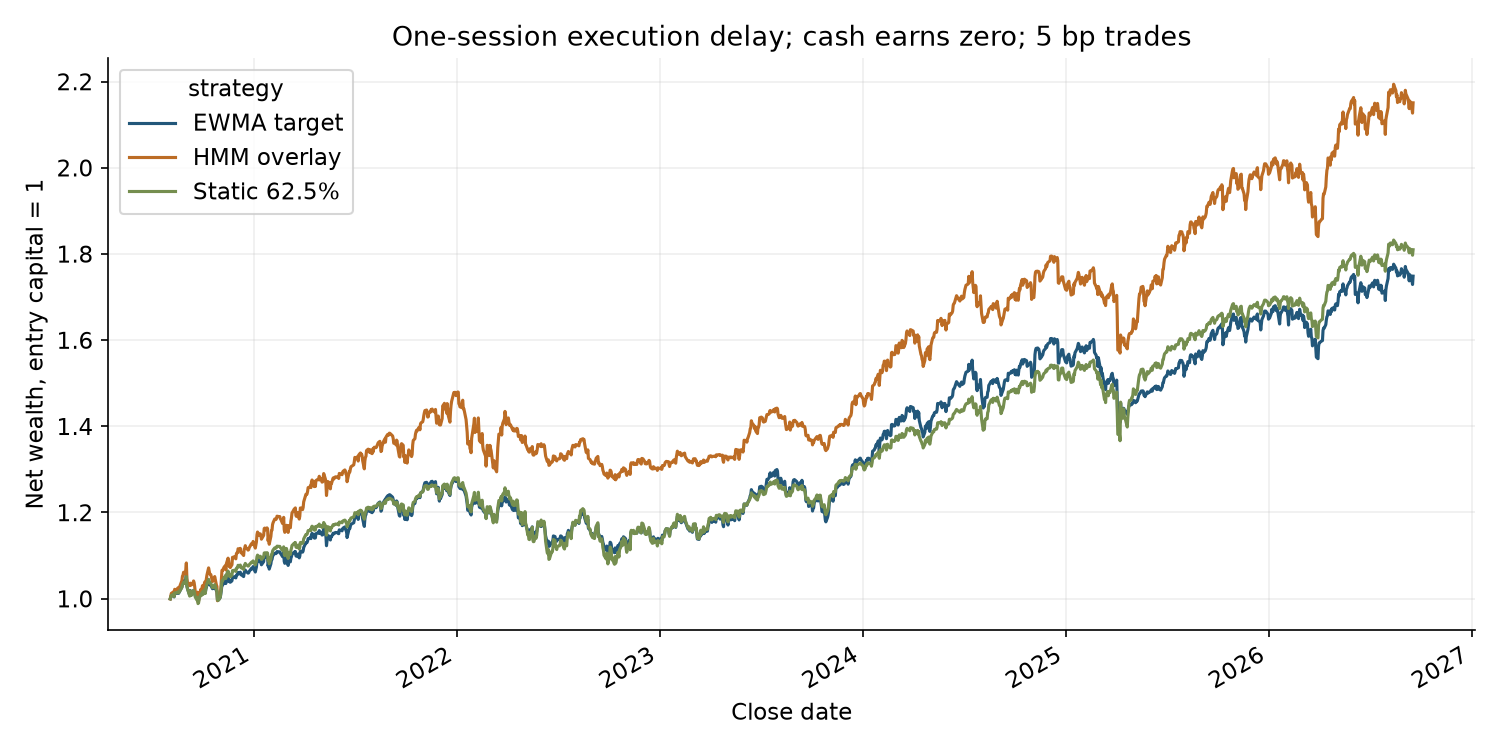

In [10]:
display(Image(filename=str(FIGURES / "overlay.png")))

### Segmentation

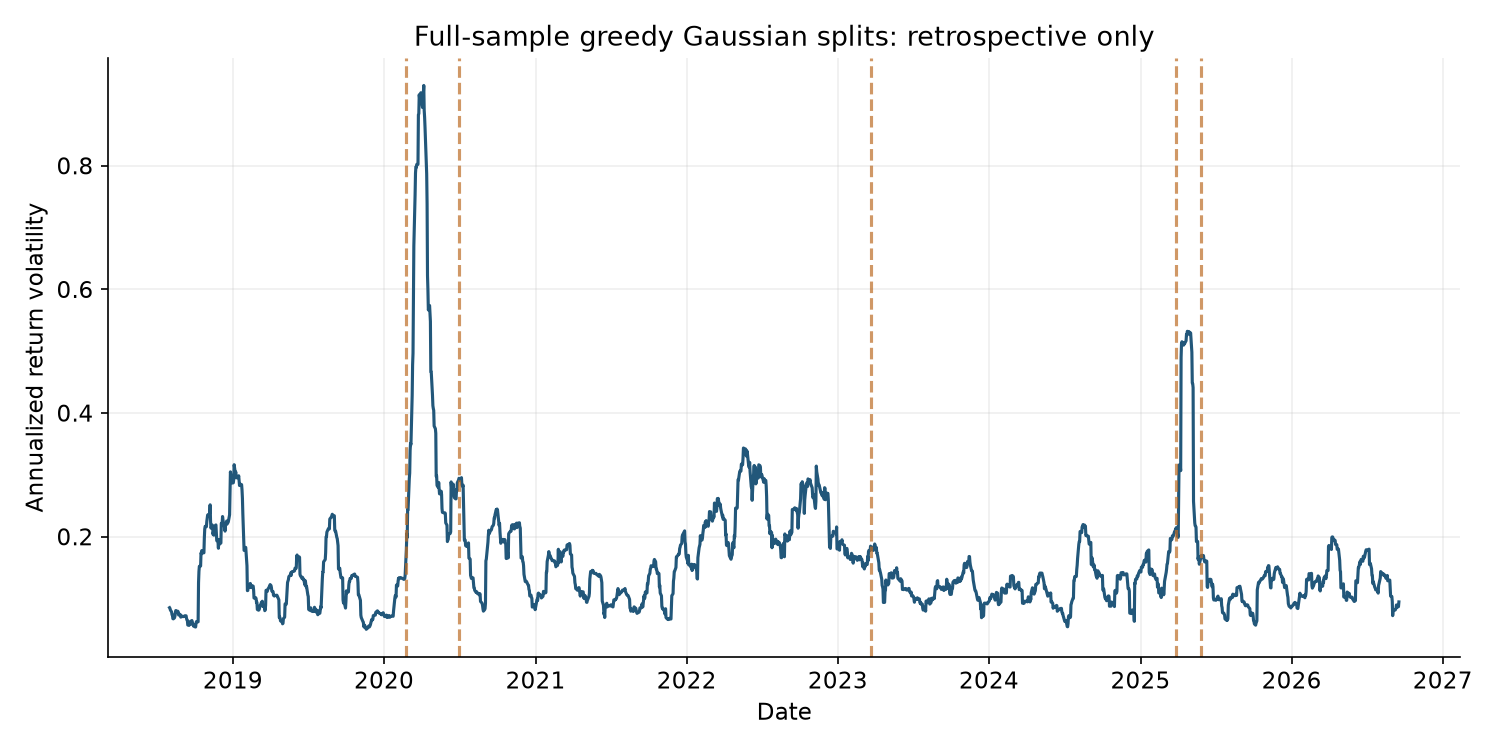

In [11]:
display(Image(filename=str(FIGURES / "segmentation.png")))

## Calculation appendix

Independently reconstruct headline values and accounting identities from saved underlying outputs, then verify source/code/artifact hashes.

In [12]:
from research.check_artifacts import independent_checks
independent_checks()

Independent saved-output calculations and source/code hashes: passed


## Takeaways and next experiment

# Next experiment — explicitly not run

The executed primary HMM/EWMA loss interval includes zero and the HMM point estimate is worse. Next, preregister a low-dimensional volatility-only state model against EWMA on genuinely new observations, with no state-count search on the test period. Preserve this negative result. Required inputs: a permitted point-in-time source snapshot, predeclared risk proxy and economic loss threshold, actual cash yields and executable timing. Separately compare online alarm delays against multiple synthetic change types rather than one large variance jump. Neither experiment has been run.


See [source register](research/SOURCES.md), [audit](research/AUDIT.md), [protocol](research/PROTOCOL.md) and [publication review](PUBLICATION.md). No live publication is part of this build.